# Modelado de datos

In [1]:
%load_ext watermark
%watermark

Last updated: 2026-11-19T21:00:30.700486-05:00

Python implementation: CPython
Python version       : 3.12.16
IPython version      : 9.17.1

Compiler    : Clang 20.1.8 
OS          : Darwin
Release     : 23.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 11
Architecture: 64bit



In [27]:
import pandas as pd
%matplotlib inline 
# no crea widget ni nada para no presentar resultados.
import pandas as pd
import numpy as np
#import matplotlib.pyplot as plt
import matplotlib as plt
import seaborn as sns
from matplotlib.pyplot import figure
import warnings
warnings.filterwarnings("ignore")


plt.rcParams['figure.figsize'] = (10,10) # 10 pulgadas de ancho y 10 de alto para todos los plots

In [28]:
bank_dp = pd.read_parquet("../output/data-bank_4_PreModeling.parquet",engine='pyarrow')

In [29]:
bank_dp.head(5)

,edad,flag_mora,prom_saldoAnual,flag_hipotecario,flag_prestamo,tipo_contacto,dia_UltContacto,cant_contactoCampanha,cant_contactoBeforeCampanha,result_campanha,...,mes_UltContacto_oct,mes_UltContacto_sep,estadoCivil_divorced,estadoCivil_married,estadoCivil_single,educacion_primary,educacion_secondary,educacion_tertiary,educacion_unknown,duracion
0,59,1,2343,1,0,2,5,1,0,0,...,False,False,False,True,False,False,True,False,False,5.0
1,56,1,45,0,0,2,5,1,0,0,...,False,False,False,True,False,False,True,False,False,5.0
2,41,1,1270,1,0,2,5,1,0,0,...,False,False,False,True,False,False,True,False,False,5.0
3,55,1,2476,1,0,2,5,1,0,0,...,False,False,False,True,False,False,True,False,False,4.0
4,54,1,184,0,0,2,5,2,0,0,...,False,False,False,True,False,False,False,True,False,5.0


In [30]:
'''Check numerical data set'''
display(bank_dp.head(3), bank_dp.shape)
display('Observamos 11152 registros y 73 columnas numéricas luego de la transformación.')

,edad,flag_mora,prom_saldoAnual,flag_hipotecario,flag_prestamo,tipo_contacto,dia_UltContacto,cant_contactoCampanha,cant_contactoBeforeCampanha,result_campanha,...,mes_UltContacto_oct,mes_UltContacto_sep,estadoCivil_divorced,estadoCivil_married,estadoCivil_single,educacion_primary,educacion_secondary,educacion_tertiary,educacion_unknown,duracion
0,59,1,2343,1,0,2,5,1,0,0,...,False,False,False,True,False,False,True,False,False,5.0
1,56,1,45,0,0,2,5,1,0,0,...,False,False,False,True,False,False,True,False,False,5.0
2,41,1,1270,1,0,2,5,1,0,0,...,False,False,False,True,False,False,True,False,False,5.0


(11152, 44)

'Observamos 11152 registros y 73 columnas numéricas luego de la transformación.'

## 1. Selecionar el resultado de la métrica

Se propone utilizar métricas ROC_AUC para evaluar diferentes modelos con monitoreo adicional de la dinámica de la métrica de precisión. 

Este enfoque nos permitirá explorar modelos desde diferentes ángulos.

## 2. Separar data de entrenamiento y test

In [6]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
import gc 

In [7]:
train_test_split?

### Muestreo Estratificado

La validación cruzada evita el sobreajuste solo si los pliegues son comparables entre sí. Si las variables más influyentes sobre la etiqueta quedan mal repartidas, los resultados no generalizan. Por eso conviene usar validación cruzada estratificada (StratifiedKFold), que conserva la misma proporción de la variable objetivo en cada partición.

In [31]:
bank_dp.result_campanha.unique()

array([0, 1], dtype=uint8)

In [32]:
bank_dp.columns

Index(['edad', 'flag_mora', 'prom_saldoAnual', 'flag_hipotecario',
       'flag_prestamo', 'tipo_contacto', 'dia_UltContacto',
       'cant_contactoCampanha', 'cant_contactoBeforeCampanha',
       'result_campanha', 'FlagTarget_DP', 'flag_ContactBeforeCamp',
       'trabajo_admin.', 'trabajo_blue-collar', 'trabajo_entrepreneur',
       'trabajo_housemaid', 'trabajo_management', 'trabajo_retired',
       'trabajo_self-employed', 'trabajo_services', 'trabajo_student',
       'trabajo_technician', 'trabajo_unemployed', 'trabajo_unknown',
       'mes_UltContacto_apr', 'mes_UltContacto_aug', 'mes_UltContacto_dec',
       'mes_UltContacto_feb', 'mes_UltContacto_jan', 'mes_UltContacto_jul',
       'mes_UltContacto_jun', 'mes_UltContacto_mar', 'mes_UltContacto_may',
       'mes_UltContacto_nov', 'mes_UltContacto_oct', 'mes_UltContacto_sep',
       'estadoCivil_divorced', 'estadoCivil_married', 'estadoCivil_single',
       'educacion_primary', 'educacion_secondary', 'educacion_tertiary',
      

Por ejemplo para el préstamo personal `flag_prestamo`:

Tener un préstamo personal es una característica importante que determina si un cliente potencial abrirá un depósito a plazo o no

Pasos para implementar muestreo estratificado:

- 1) Necesitamos ver cómo se distribuyen nuestros datos. 
- 2) Después de notar que la columna de préstamo contiene 87% de "no" (No tiene préstamos personales) y 13% de "sí" (Tiene préstamos personales). 
- 3) Queremos asegurarnos de que nuestro conjunto de entrenamiento y prueba contenga la misma proporción de 87% "no" y 13% "sí".

Distribuciión de `flag_prestamo`

In [33]:
bank_dp["flag_prestamo"].value_counts()/len(bank_dp)

flag_prestamo
0    0.86944
1    0.13056
Name: count, dtype: float64

In [34]:
X = bank_dp.drop(columns = 'FlagTarget_DP')
y = bank_dp[['FlagTarget_DP']]

In [12]:
gc?

In [35]:
''' Split data on train and test'''
# set global random state
random_state = 42
# split data
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_state ,shuffle=False)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_state)
# collect excess data
gc.collect()

24

In [36]:
train_test_split?

Signature:
train_test_split(
    *arrays,
    test_size=None,
    train_size=None,
    random_state=None,
    shuffle=True,
    stratify=None,
)
Docstring:
Split arrays or matrices into random train and test subsets.

Quick utility that wraps input validation,
``next(ShuffleSplit().split(X, y))``, and application to input data
into a single call for splitting (and optionally subsampling) data into a
one-liner.

Read more in the :ref:`User Guide <cross_validation>`.

Parameters
----------
*arrays : sequence of array-like of shape (n_samples,) or             (n_samples, n_outputs)
    Indexable data-structures can be arrays, lists, dataframes, scipy
    sparse matrices or pandas dataframes with consistent first dimension.

test_size : float or int, default=None
    If float, should be between 0.0 and 1.0 and represent the proportion
    of the dataset to include in the test split. If int, represents the
    absolute number of test samples. If None, the value is set to the
    complement 

Comprobar el muestreo estratificado

In [37]:
X_train["flag_prestamo"].value_counts()/len(X_train)

flag_prestamo
0    0.870194
1    0.129806
Name: count, dtype: float64

In [38]:
y_train["FlagTarget_DP"].value_counts()/len(y_train)

FlagTarget_DP
0    0.525838
1    0.474162
Name: count, dtype: float64

In [39]:
X_test["flag_prestamo"].value_counts()/len(X_test)

flag_prestamo
0    0.866428
1    0.133572
Name: count, dtype: float64

In [40]:
y_test["FlagTarget_DP"].value_counts()/len(y_test)

FlagTarget_DP
0    0.526221
1    0.473779
Name: count, dtype: float64

Si se compara la distribución del dataset para (x,y) train como para test las distribuciones son similares, de esta manera vemos que los datos una distribución similarmente alta.

In [41]:
display('El tamaño de los datos sepadaso en train y test son:', X_train.shape, y_train.shape, X_test.shape, y_test.shape)

'El tamaño de los datos sepadaso en train y test son:'

(8921, 43)

(8921, 1)

(2231, 43)

(2231, 1)

## 3. Modelado

### 3.1. Nota sobre el algoritmo de Árbol de Decisión

Para el árbol de decisión se emplea el algoritmo **CART** (*Classification and Regression Trees*), que es la implementación disponible en `DecisionTreeClassifier` de scikit-learn. Se documenta así explícitamente para mantener la coherencia entre el objetivo, la implementación y los resultados.

Todos los modelos se entrenan con `random_state=42` para garantizar la reproducibilidad. Las variables auxiliares `Rango_edad` y `duration_status`, creadas únicamente para el análisis exploratorio (EDA), se excluyen del modelado por ser derivadas de `edad` y `seg_UltContacto`, que ya están presentes.

Se eliminan las variables auxiliares del EDA antes de entrenar.

In [42]:
# Eliminar variables auxiliares del EDA (derivadas, solo para análisis)
cols_aux = [c for c in ['Rango_edad','duration_status'] if c in bank_dp.columns]
bank_dp = bank_dp.drop(columns=cols_aux)
print('Columnas auxiliares eliminadas:', cols_aux)
print('Shape para modelado:', bank_dp.shape)

Columnas auxiliares eliminadas: []
Shape para modelado: (11152, 44)


Partición estratificada 80/20 con semilla fija.

In [43]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
X = bank_dp.drop(columns='FlagTarget_DP')
y = bank_dp['FlagTarget_DP']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (8921, 43) | Test: (2231, 43)


Escalado estándar para los modelos sensibles a la escala (Regresión Logística y SVM).

In [44]:
scaler = StandardScaler().fit(X_train)
X_train_sc = scaler.transform(X_train)
X_test_sc  = scaler.transform(X_test)
X_sc       = scaler.transform(X)   # para validación cruzada

In [45]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

### 3.2. Definición de los cuatro modelos

In [46]:
modelos = {
    'Árbol de Decisión (CART)': (DecisionTreeClassifier(random_state=RANDOM_STATE), False),
    'Regresión Logística':      (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), True),
    'Naïve Bayes':              (GaussianNB(), False),
    'SVM':                      (SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE), True),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [47]:
resultados = []
for nombre, (modelo, escalar) in modelos.items():
    Xtr = X_train_sc if escalar else X_train.values
    Xte = X_test_sc  if escalar else X_test.values
    Xcv = X_sc       if escalar else X.values
    modelo.fit(Xtr, y_train)
    y_pred  = modelo.predict(Xte)
    y_proba = modelo.predict_proba(Xte)[:, 1]
    acc_train = accuracy_score(y_train, modelo.predict(Xtr))
    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec  = recall_score(y_test, y_pred)
    f1   = f1_score(y_test, y_pred)
    auc  = roc_auc_score(y_test, y_proba)
    cm   = confusion_matrix(y_test, y_pred)
    cvs  = cross_val_score(modelo, Xcv, y, cv=cv, scoring='accuracy')
    resultados.append({'modelo':nombre,'accuracy':acc,'precision':prec,'recall':rec,
                       'f1':f1,'auc':auc,'accuracy_train':acc_train,
                       'cv_mean':cvs.mean(),'cv_std':cvs.std(),
                       'y_pred':y_pred,'y_proba':y_proba,'cm':cm})
    print(f'\n=== {nombre} ===')
    print(f'  Entrenamiento (accuracy): {acc_train:.4f}')
    print(f'  Prueba  -> accuracy={acc:.4f}  precision={prec:.4f}  recall={rec:.4f}  f1={f1:.4f}  auc={auc:.4f}')
    print(f'  Validación cruzada (5) -> media={cvs.mean():.4f}  desv.est.={cvs.std():.4f}')
    print(f'  Matriz de confusión: {cm.tolist()}')


=== Árbol de Decisión (CART) ===
  Entrenamiento (accuracy): 1.0000
  Prueba  -> accuracy=0.7768  precision=0.7738  recall=0.7474  f1=0.7603  auc=0.7753
  Validación cruzada (5) -> media=0.7747  desv.est.=0.0044
  Matriz de confusión: [[943, 231], [267, 790]]

=== Regresión Logística ===
  Entrenamiento (accuracy): 0.8177
  Prueba  -> accuracy=0.8158  precision=0.7963  recall=0.8212  f1=0.8086  auc=0.8965
  Validación cruzada (5) -> media=0.8142  desv.est.=0.0044
  Matriz de confusión: [[952, 222], [189, 868]]

=== Naïve Bayes ===
  Entrenamiento (accuracy): 0.7043
  Prueba  -> accuracy=0.7122  precision=0.7960  recall=0.5279  f1=0.6348  auc=0.8213
  Validación cruzada (5) -> media=0.7044  desv.est.=0.0038
  Matriz de confusión: [[1031, 143], [499, 558]]

=== SVM ===
  Entrenamiento (accuracy): 0.8751
  Prueba  -> accuracy=0.8337  precision=0.8030  recall=0.8600  f1=0.8305  auc=0.9122
  Validación cruzada (5) -> media=0.8364  desv.est.=0.0038
  Matriz de confusión: [[951, 223], [148, 

### 3.3. Tabla comparativa de métricas

In [49]:
tabla = pd.DataFrame(resultados)
tabla = tabla.sort_values('accuracy', ascending=False)
tabla_fmt = tabla[['modelo','accuracy','precision','recall','f1','auc','cv_mean','cv_std']].round(4)
tabla_fmt.columns = ['Modelo','Accuracy','Precision','Recall','F1','AUC','CV_media','CV_std']
print(tabla_fmt.to_string(index=False))

                  Modelo  Accuracy  Precision  Recall     F1    AUC  CV_media  CV_std
                     SVM    0.8337     0.8030  0.8600 0.8305 0.9122    0.8364  0.0038
     Regresión Logística    0.8158     0.7963  0.8212 0.8086 0.8965    0.8142  0.0044
Árbol de Decisión (CART)    0.7768     0.7738  0.7474 0.7603 0.7753    0.7747  0.0044
             Naïve Bayes    0.7122     0.7960  0.5279 0.6348 0.8213    0.7044  0.0038


#### Visualización comparativa de métricas

Las cinco métricas (`accuracy`, `precision`, `recall`, `F1`, `AUC`) se grafican a partir de la lista `resultados` para comparar los cuatro modelos de un vistazo. El PNG se guarda en `../output/fig_metricas_comparacion.png`.

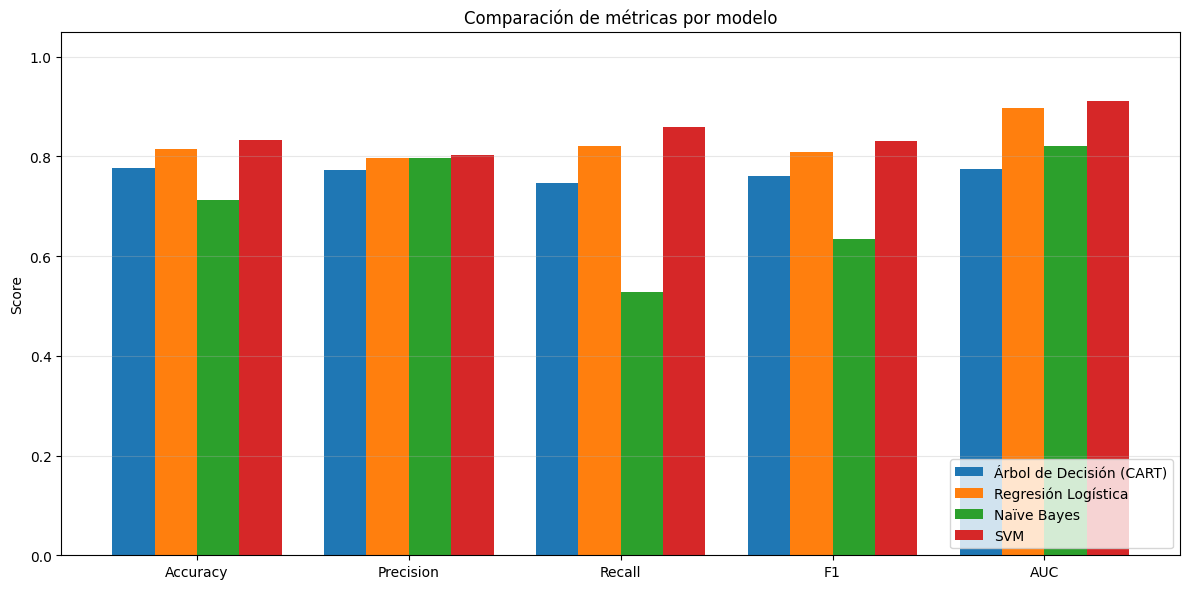

In [50]:
import matplotlib.pyplot as plt
import numpy as np

metricas = ['accuracy','precision','recall','f1','auc']
labels   = ['Accuracy','Precision','Recall','F1','AUC']
nombres  = [r['modelo'] for r in resultados]
valores  = np.array([[r[m] for m in metricas] for r in resultados])

x = np.arange(len(metricas))
w = 0.8 / len(nombres)
fig, ax = plt.subplots(figsize=(12, 6))
for i, nombre in enumerate(nombres):
    ax.bar(x + (i - (len(nombres)-1)/2) * w, valores[i], w, label=nombre)
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylim(0, 1.05); ax.set_ylabel('Score')
ax.set_title('Comparación de métricas por modelo')
ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../output/fig_metricas_comparacion.png', dpi=120, bbox_inches='tight')
plt.show()

### 3.4. Análisis del sobreajuste (objetivo específico 3)

Si un modelo tiene un desempeño mucho mejor en entrenamiento que en validación cruzada, está **sobreajustando**: memoriza los datos de entrenamiento y no generaliza. La celda siguiente calcula esa brecha (`accuracy_train` − `cv_mean`) por modelo, y el gráfico la muestra visualmente.

In [51]:
print('Brecha entrenamiento vs validación cruzada (indicador de sobreajuste):')
for r in resultados:
    gap = r['accuracy_train'] - r['cv_mean']
    print(f"  {r['modelo']:<26} train={r['accuracy_train']:.4f}  cv={r['cv_mean']:.4f}  brecha={gap:+.4f}")

Brecha entrenamiento vs validación cruzada (indicador de sobreajuste):
  Árbol de Decisión (CART)   train=1.0000  cv=0.7747  brecha=+0.2253
  Regresión Logística        train=0.8177  cv=0.8142  brecha=+0.0035
  Naïve Bayes                train=0.7043  cv=0.7044  brecha=-0.0001
  SVM                        train=0.8751  cv=0.8364  brecha=+0.0387


#### Diagnóstico visual del sobreajuste

Barras pareadas de train vs validación cruzada con la brecha anotada encima.

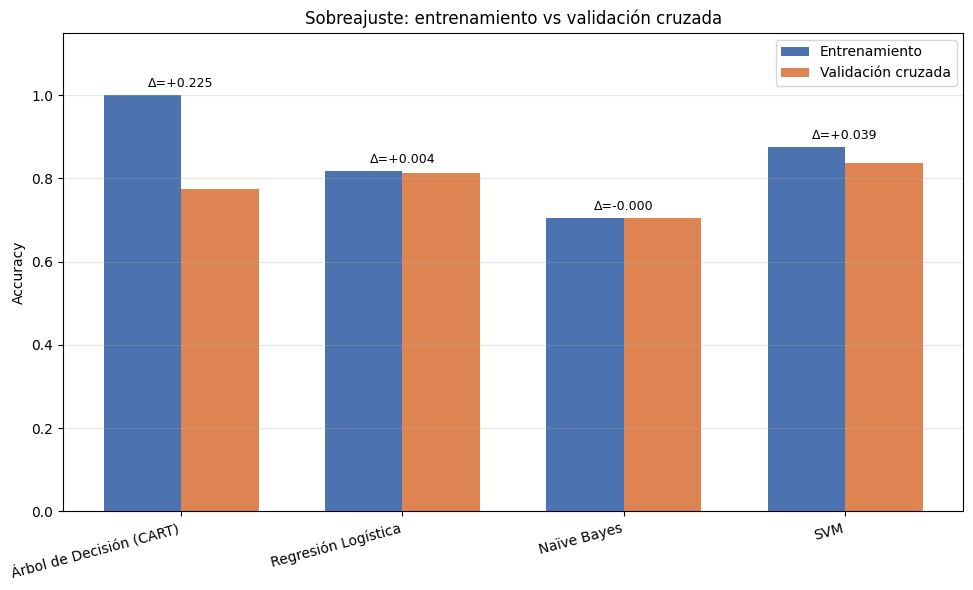

In [52]:
import matplotlib.pyplot as plt
import numpy as np

nombres = [r['modelo'] for r in resultados]
train   = [r['accuracy_train'] for r in resultados]
cv_m    = [r['cv_mean'] for r in resultados]
brecha  = [t - c for t, c in zip(train, cv_m)]

x = np.arange(len(nombres)); w = 0.35
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - w/2, train, w, label='Entrenamiento', color='#4C72B0')
ax.bar(x + w/2, cv_m,  w, label='Validación cruzada', color='#DD8452')
for xi, (t, c, g) in enumerate(zip(train, cv_m, brecha)):
    ax.annotate(f'Δ={g:+.3f}', (xi, max(t, c) + 0.02), ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(nombres, rotation=15, ha='right')
ax.set_ylim(0, 1.15); ax.set_ylabel('Accuracy')
ax.set_title('Sobreajuste: entrenamiento vs validación cruzada')
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../output/fig_overfitting.png', dpi=120, bbox_inches='tight')
plt.show()

### 3.5. Matrices de confusión

Cada matriz usa el `cm` guardado dentro de `resultados` para mostrar aciertos y errores por clase (`0 = no abre depósito`, `1 = abre depósito`).

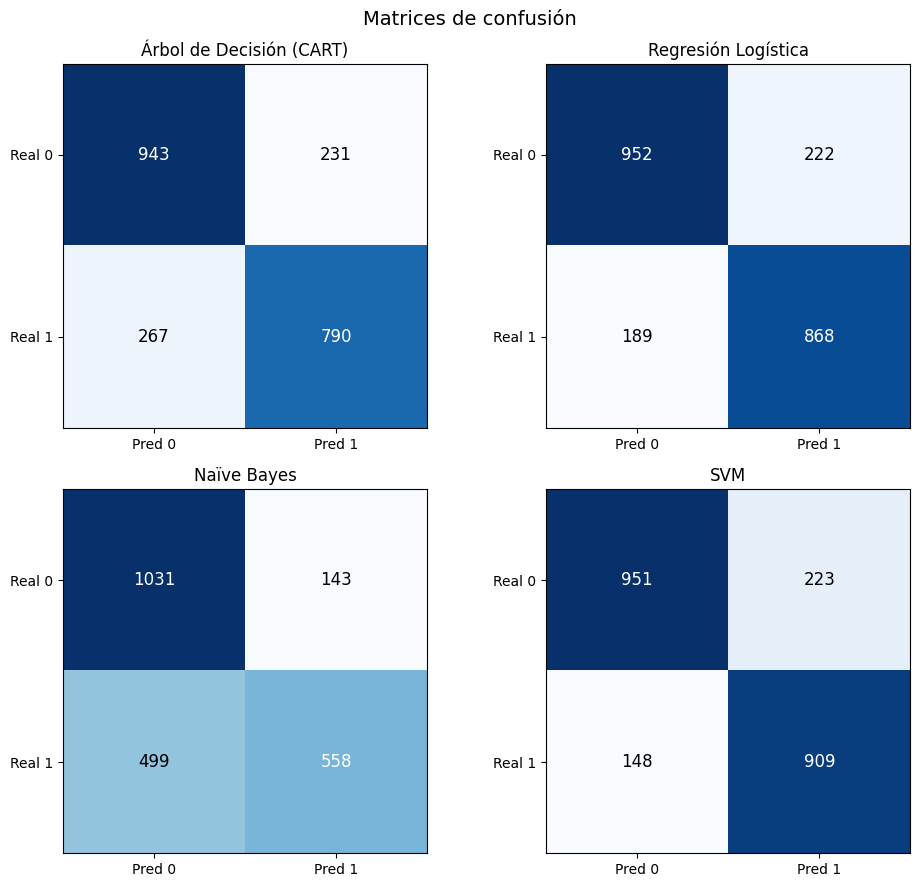

In [53]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, r in zip(axes.ravel(), resultados):
    cm = np.array(r['cm'])
    ax.imshow(cm, cmap='Blues')
    ax.set_title(r['modelo'])
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['Pred 0', 'Pred 1'])
    ax.set_yticklabels(['Real 0', 'Real 1'])
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, str(v), ha='center', va='center',
                color='white' if v > cm.max() / 2 else 'black', fontsize=12)
plt.suptitle('Matrices de confusión', fontsize=14)
plt.tight_layout()
plt.savefig('../output/fig_matrices_confusion.png', dpi=120, bbox_inches='tight')
plt.show()

### 3.6. Curva ROC

Se grafican las cuatro curvas ROC usando el `y_proba` guardado por modelo y `y_test`. El AUC se toma directo de `resultados`.

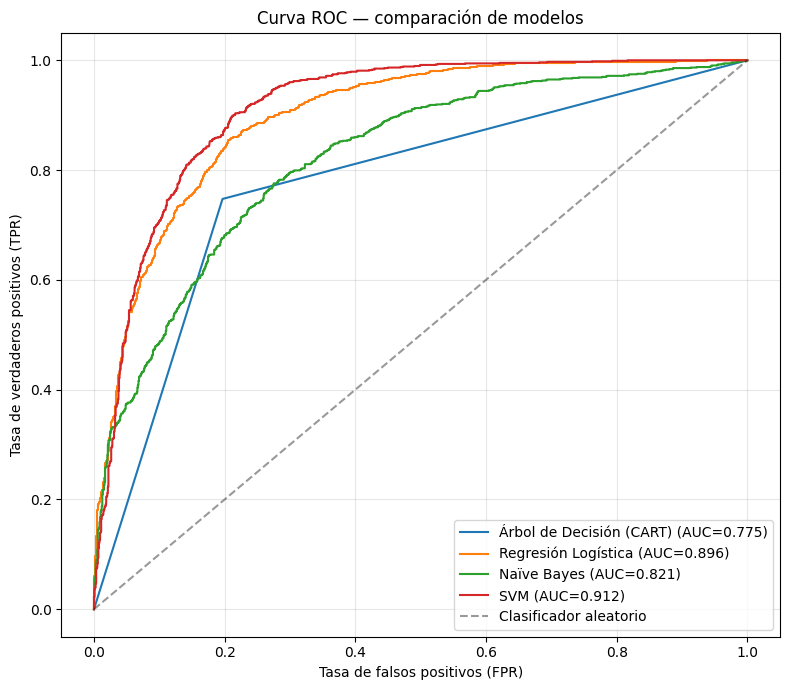

In [54]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(8, 7))
for r in resultados:
    fpr, tpr, _ = roc_curve(y_test, r['y_proba'])
    ax.plot(fpr, tpr, label=f"{r['modelo']} (AUC={r['auc']:.3f})")
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Clasificador aleatorio')
ax.set_xlabel('Tasa de falsos positivos (FPR)')
ax.set_ylabel('Tasa de verdaderos positivos (TPR)')
ax.set_title('Curva ROC — comparación de modelos')
ax.legend(loc='lower right'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../output/fig_curva_ROC.png', dpi=120, bbox_inches='tight')
plt.show()

### 3.7. Información de reproducibilidad

In [55]:
import sklearn, sys
print('Python      :', sys.version.split()[0])
print('scikit-learn:', sklearn.__version__)
print('Semilla (random_state):', RANDOM_STATE)
print('Validación cruzada: StratifiedKFold(n_splits=5, shuffle=True, random_state=42)')

Python      : 3.12.16
scikit-learn: 1.9.1
Semilla (random_state): 42
Validación cruzada: StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
